In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
X, y_true = make_blobs(n_samples=100, centers=3, cluster_std=0.60, random_state=42)

In [3]:
df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])

In [4]:
df.head()

,Feature_1,Feature_2
0,-7.387703,-7.789018
1,5.127989,1.234651
2,-2.790882,9.339822
3,5.481555,1.132059
4,-6.664955,-6.543639


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [6]:
inertia = []
K_range = range(1, 11)

In [7]:
for K in K_range:
  k_mean = KMeans(n_clusters=K, random_state=42)
  k_mean.fit(X_scaled)
  inertia.append(k_mean.inertia_)

In [8]:
inertia

[200.0,
 59.93027512966683,
 2.0331401136396368,
 1.7440678422876639,
 1.482640696254919,
 1.3907613511330106,
 1.142270509765479,
 0.9740243472092616,
 0.9155190035597232,
 0.7641617436454582]

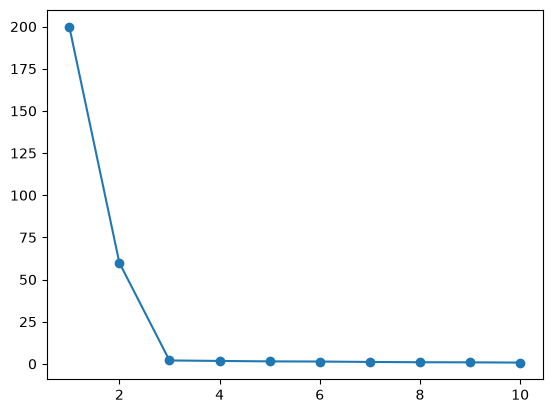

In [9]:
plt.plot(K_range, inertia, marker='o')

In [10]:
kmean_final = KMeans(n_clusters=3, random_state=42)

In [11]:
cluster_labels = kmean_final.fit_predict(X_scaled)

In [12]:
df["cluster"] = cluster_labels

In [13]:
df.head()

,Feature_1,Feature_2,cluster
0,-7.387703,-7.789018,1
1,5.127989,1.234651,2
2,-2.790882,9.339822,0
3,5.481555,1.132059,2
4,-6.664955,-6.543639,1


<Axes: xlabel='Feature_1', ylabel='Feature_2'>

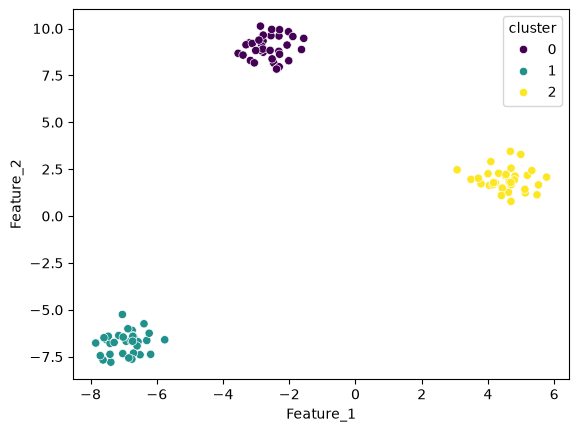

In [14]:
sns.scatterplot(
  x=df["Feature_1"],
  y=df["Feature_2"],
  hue=df["cluster"],
  palette="viridis"
)

In [15]:
from sklearn.datasets import make_moons

In [16]:
X, y_true = make_moons(n_samples=500, noise=0.05, random_state=42)

In [17]:
from sklearn.cluster import KMeans, DBSCAN

In [18]:
df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])

In [19]:
df.head()

,Feature_1,Feature_2
0,0.830586,-0.447733
1,0.701678,0.816918
2,1.022080,-0.492571
3,-0.316765,0.953438
4,0.293226,1.057185


In [22]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [23]:
Kmeans = KMeans(n_clusters=2, random_state=42)
Kmeans_label = Kmeans.fit_predict(X_scaled)

In [24]:
df["kmeans_cluster"] = Kmeans_label

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

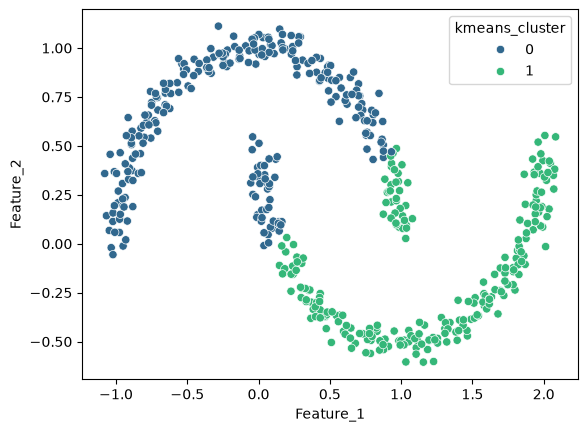

In [25]:
sns.scatterplot(
  x=df["Feature_1"],
  y=df["Feature_2"],
  hue=df["kmeans_cluster"],
  palette="viridis"
)

In [31]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbs_labels = dbscan.fit_predict(X_scaled)
df["dbs_cluster"] = dbs_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

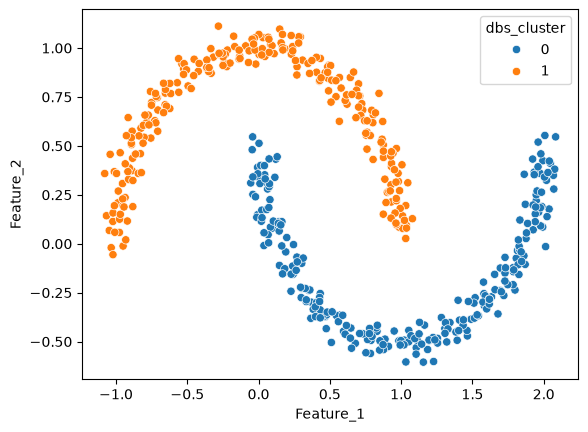

In [32]:
sns.scatterplot(
  x=df["Feature_1"],
  y=df["Feature_2"],
  hue=df["dbs_cluster"]
)